# Single 30-Day Garmin Sample Processing

This notebook processes **one 30-day sample** from the Garmin wearable dataset.

It is designed for a file containing approximately:

- 30 rows
- one participant/sample
- one row per day
- the same Garmin feature columns used in the full dataset

The notebook removes analyses that require multiple participants, including:

- between-participant comparisons
- class-distribution analysis
- group comparisons by outcome
- cross-validation
- participant-level classification evaluation

It retains analyses that are useful for one 30-day sequence:

- structure and duplicate checks
- robust time conversion
- missing-value analysis
- descriptive statistics
- daily time-series plots
- trend slopes
- rolling averages
- within-sample z-scores
- outlier checks
- correlation analysis
- aeon-ready array creation


## 1. Install required packages

In [ ]:
# Run only if required.
%pip install pandas numpy matplotlib odfpy


## 2. Imports

In [72]:
from pathlib import Path
import datetime
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)


## 3. Set the file path

Place the single-sample file in the same folder as this notebook.

The file may be:

- `.ods`
- `.xlsx`
- `.csv`


In [ ]:
FILE_PATH = Path("../data/Report Sample 31 (Injured).csv")

if not FILE_PATH.exists():
    raise FileNotFoundError(
        f"Could not find the file at: {FILE_PATH.resolve()}"
    )

print("File found:", FILE_PATH.resolve())


## 4. Load the file

In [74]:
file_suffix = FILE_PATH.suffix.lower()

if file_suffix == ".ods":
    df_raw = pd.read_excel(
        FILE_PATH,
        engine="odf"
    )
elif file_suffix in [".xlsx", ".xls"]:
    df_raw = pd.read_excel(FILE_PATH)
elif file_suffix == ".csv":
    df_raw = pd.read_csv(FILE_PATH)
else:
    raise ValueError(
        "Unsupported file type. Use ODS, XLSX, XLS or CSV."
    )

print("File loaded successfully.")
print("Raw shape:", df_raw.shape)

display(df_raw.head())


File loaded successfully.
Raw shape: (30, 20)


,day_no,run_count,end_of_sample_status,running_distance_km,running_elapsed_time,avg_ground_contact_ms,avg_cadence_spm,avg_running_heart_rate_bpm,avg_elapsed_pace_min_per_km,avg_stride_length_m,resting_heart_rate_bpm,avg_stress_level,nightly_hrv_ms,weekly_avg_hrv_ms,sleep_duration,sleep_score,deep_sleep_duration,light_sleep_duration,rem_sleep_duration,awake_duration
0,1,1,injured,12.12,01:03,243.0,169.6,139.0,05:11,1.294,41,20,117,96,08:12,75,00:36,04:34,03:02,00:02
1,2,1,injured,9.91,00:46,239.7,173.3,145.0,04:40,1.273,45,23,106,98,08:10,73,00:00,05:04,03:06,00:04
2,3,0,injured,NaN,NaN,NaN,NaN,NaN,NaN,NaN,47,27,95,99,09:49,81,00:51,05:44,03:14,00:01
3,4,1,injured,10.00,00:45,232.8,172.5,151.0,04:30,1.353,44,22,100,100,09:16,78,00:14,05:30,03:32,00:10
4,5,0,injured,NaN,NaN,NaN,NaN,NaN,NaN,NaN,44,22,101,101,05:49,62,00:33,03:51,01:25,00:02


## 5. Rename columns

In [75]:
COLUMN_MAP = {
    "sample_no": "participant_id",
    "day_no": "day_number",
    "end_of_sample_status": "status",
    "run_count": "run_count",
    "running_distance_km": "distance",
    "running_elapsed_time": "elapsed_time",
    "avg_ground_contact_ms": "ground_contact_time",
    "avg_cadence_spm": "cadence",
    "avg_running_heart_rate_bpm": "running_heart_rate",
    "avg_elapsed_pace_min_per_km": "elapsed_pace",
    "avg_stride_length_m": "stride_length",
    "resting_heart_rate_bpm": "resting_heart_rate",
    "avg_stress_level": "stress",
    "nightly_hrv_ms": "nightly_hrv",
    "weekly_avg_hrv_ms": "weekly_hrv",
    "sleep_duration": "sleep_duration",
    "sleep_score": "sleep_score",
    "deep_sleep_duration": "deep_sleep",
    "light_sleep_duration": "light_sleep",
    "rem_sleep_duration": "rem_sleep",
    "awake_duration": "awake_duration",
}

available_mapping = {
    original: renamed
    for original, renamed in COLUMN_MAP.items()
    if original in df_raw.columns
}

df = (
    df_raw
    .rename(columns=available_mapping)
    .drop(columns=["Unnamed: 3", "Unnamed: 12"], errors="ignore")
    .copy()
)

print("Columns after renaming:")
print(df.columns.tolist())


Columns after renaming:
['day_number', 'run_count', 'status', 'distance', 'elapsed_time', 'ground_contact_time', 'cadence', 'running_heart_rate', 'elapsed_pace', 'stride_length', 'resting_heart_rate', 'stress', 'nightly_hrv', 'weekly_hrv', 'sleep_duration', 'sleep_score', 'deep_sleep', 'light_sleep', 'rem_sleep', 'awake_duration']


## 6. Check required columns

In [76]:
required_columns = [
    "day_number",
    "run_count",
    "distance",
    "elapsed_time",
    "ground_contact_time",
    "cadence",
    "running_heart_rate",
    "elapsed_pace",
    "stride_length",
    "resting_heart_rate",
    "stress",
    "nightly_hrv",
    "weekly_hrv",
    "sleep_duration",
    "sleep_score",
    "deep_sleep",
    "light_sleep",
    "rem_sleep",
    "awake_duration",
]

missing_required_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_required_columns:
    raise KeyError(
        "Missing required columns: "
        + ", ".join(missing_required_columns)
    )

print("All required feature columns were found.")


All required feature columns were found.


## 7. Robust time conversion

In [77]:
# Convert HH:MM or HH:MM:SS durations into minutes
def duration_to_minutes(value):
    if pd.isna(value):
        return np.nan

    text = str(value).strip()
    parts = text.split(":")

    try:
        if len(parts) == 2:
            hours = float(parts[0])
            minutes = float(parts[1])
            seconds = 0

        elif len(parts) == 3:
            hours = float(parts[0])
            minutes = float(parts[1])
            seconds = float(parts[2])

        else:
            return np.nan

        return hours * 60 + minutes + seconds / 60

    except (ValueError, TypeError):
        return np.nan


# Convert MM:SS running pace into seconds per kilometre
def pace_to_seconds(value):
    if pd.isna(value):
        return np.nan

    text = str(value).strip()
    parts = text.split(":")

    try:
        if len(parts) == 2:
            minutes = float(parts[0])
            seconds = float(parts[1])

        elif len(parts) == 3:
            hours = float(parts[0])
            minutes = hours * 60 + float(parts[1])
            seconds = float(parts[2])

        else:
            return np.nan

        return minutes * 60 + seconds

    except (ValueError, TypeError):
        return np.nan


# Convert identifiers
df["day_number"] = pd.to_numeric(
    df["day_number"],
    errors="raise"
).astype(int)

if "participant_id" in df.columns:
    df["participant_id"] = pd.to_numeric(
        df["participant_id"],
        errors="coerce"
    )

df["status"] = (
    df["status"]
    .astype(str)
    .str.strip()
)


# Convert duration columns to minutes
duration_columns = [
    "elapsed_time",
    "sleep_duration",
    "deep_sleep",
    "light_sleep",
    "rem_sleep",
    "awake_duration",
]

for column in duration_columns:
    df[column] = df[column].apply(
        duration_to_minutes
    )


# Convert pace to seconds per kilometre
df["elapsed_pace"] = df["elapsed_pace"].apply(
    pace_to_seconds
)


# Convert remaining columns to numeric values
numeric_columns = [
    "run_count",
    "distance",
    "ground_contact_time",
    "cadence",
    "running_heart_rate",
    "stride_length",
    "resting_heart_rate",
    "stress",
    "nightly_hrv",
    "weekly_hrv",
    "sleep_score",
]

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )


# Sort the 30 days
df = (
    df.sort_values("day_number")
    .reset_index(drop=True)
)


# Display the converted values
time_check_columns = [
    "day_number",
    "elapsed_time",
    "elapsed_pace",
    "sleep_duration",
    "deep_sleep",
    "light_sleep",
    "rem_sleep",
    "awake_duration",
]

print("Time conversion completed.")

display(
    df[time_check_columns].head()
)

Time conversion completed.


,day_number,elapsed_time,elapsed_pace,sleep_duration,deep_sleep,light_sleep,rem_sleep,awake_duration
0,1,63.0,311.0,492.0,36.0,274.0,182.0,2.0
1,2,46.0,280.0,490.0,0.0,304.0,186.0,4.0
2,3,NaN,NaN,589.0,51.0,344.0,194.0,1.0
3,4,45.0,270.0,556.0,14.0,330.0,212.0,10.0
4,5,NaN,NaN,349.0,33.0,231.0,85.0,2.0


## 8. Convert data types

## 9. Verify the 30-day structure

In [78]:
print("Number of rows:", len(df))
print("Minimum day number:", df["day_number"].min())
print("Maximum day number:", df["day_number"].max())
print("Unique day numbers:", df["day_number"].nunique())

if len(df) != 30:
    print(
        "Warning: the file does not contain exactly 30 rows."
    )

if df["day_number"].nunique() != 30:
    print(
        "Warning: there are missing or duplicated day numbers."
    )

expected_days = set(range(1, 31))
actual_days = set(df["day_number"])

missing_days = sorted(expected_days - actual_days)
extra_days = sorted(actual_days - expected_days)

print("Missing days:", missing_days)
print("Unexpected day numbers:", extra_days)


Number of rows: 30
Minimum day number: 1
Maximum day number: 30
Unique day numbers: 30
Missing days: []
Unexpected day numbers: []


## Effort index 

In [79]:
df["effort_index"] = np.where(
    (df["elapsed_pace"].notna()) &
    (df["running_heart_rate"].notna()) &
    (df["elapsed_pace"] > 0),

    df["running_heart_rate"] / df["elapsed_pace"],

    np.nan
)

print("Effort Index feature created.")

display(
    df[
        [
            "elapsed_pace",
            "running_heart_rate",
            "effort_index"
        ]
    ].head()
)

Effort Index feature created.


,elapsed_pace,running_heart_rate,effort_index
0,311.0,139.0,0.446945
1,280.0,145.0,0.517857
2,NaN,NaN,NaN
3,270.0,151.0,0.559259
4,NaN,NaN,NaN


## Mileage build (%)

In [80]:
df["weekly_distance_km"] = (
    df["distance"]
    .fillna(0)
    .rolling(
        window=7,
        min_periods=7
    )
    .sum()
)

# Distance from the previous non-overlapping 7-day period
df["previous_week_distance_km"] = (
    df["weekly_distance_km"]
    .shift(7)
)

# Percentage change in weekly mileage
df["weekly_mileage_change_pct"] = np.where(
    df["previous_week_distance_km"] > 0,

    (
        (
            df["weekly_distance_km"]
            - df["previous_week_distance_km"]
        )
        / df["previous_week_distance_km"]
    )
    * 100,

    np.nan
)

display(
    df[
        [
            "day_number",
            "distance",
            "weekly_distance_km",
            "previous_week_distance_km",
            "weekly_mileage_change_pct"
        ]
    ].head()
)

,day_number,distance,weekly_distance_km,previous_week_distance_km,weekly_mileage_change_pct
0,1,12.12,NaN,NaN,NaN
1,2,9.91,NaN,NaN,NaN
2,3,NaN,NaN,NaN,NaN
3,4,10.00,NaN,NaN,NaN
4,5,NaN,NaN,NaN,NaN


## Chronic Load 

In [81]:
# =====================================================
# Chronic Load + Acute/Chronic Load Ratio
# =====================================================

distance_for_load = df["distance"].fillna(0)

# 7-day acute load
df["acute_load_km"] = (
    distance_for_load
    .rolling(
        window=7,
        min_periods=7
    )
    .sum()
)

# 28-day chronic load average per week
df["chronic_load_km"] = (
    distance_for_load
    .rolling(
        window=28,
        min_periods=28
    )
    .sum()
    / 4
)

# Load ratio
df["load_ratio"] = np.where(
    df["chronic_load_km"] > 0,
    df["acute_load_km"] / df["chronic_load_km"],
    np.nan
)

display(
    df[
        [
            "day_number",
            "distance",
            "acute_load_km",
            "chronic_load_km",
            "load_ratio"
        ]
    ]
)

valid_ratio = df["load_ratio"].dropna()

if not valid_ratio.empty:
    print(
        f"Final Load Ratio: "
        f"{valid_ratio.iloc[-1]:.2f}"
    )

    print(
        f"Highest Load Ratio: "
        f"{valid_ratio.max():.2f}"
    )

    print(
        f"Average Load Ratio: "
        f"{valid_ratio.mean():.2f}"
    )

    print(
        "Days above 1.2:",
        int((valid_ratio > 1.2).sum())
    )

,day_number,distance,acute_load_km,chronic_load_km,load_ratio
0,1,12.12,NaN,NaN,NaN
1,2,9.91,NaN,NaN,NaN
2,3,NaN,NaN,NaN,NaN
3,4,10.00,NaN,NaN,NaN
4,5,NaN,NaN,NaN,NaN
5,6,6.72,NaN,NaN,NaN
6,7,6.97,45.72,NaN,NaN
7,8,16.88,50.48,NaN,NaN
8,9,11.28,51.85,NaN,NaN
9,10,20.22,72.07,NaN,NaN


Final Load Ratio: 0.77
Highest Load Ratio: 0.94
Average Load Ratio: 0.85
Days above 1.2: 0


## HRV Deviation

In [82]:
# =====================================================
# HRV Deviation + Trend
# =====================================================

# Difference between nightly HRV and weekly baseline
df["hrv_deviation"] = (
    df["nightly_hrv"]
    - df["weekly_hrv"]
)

# Remove missing values
hrv_data = df[
    [
        "day_number",
        "hrv_deviation"
    ]
].dropna()

if len(hrv_data) >= 2:

    # Linear trend
    hrv_slope, hrv_intercept = np.polyfit(
        hrv_data["day_number"],
        hrv_data["hrv_deviation"],
        1
    )

    # Save as a feature (same value repeated for all rows)
    df["hrv_trend"] = hrv_slope

    print(f"HRV trend: {hrv_slope:.3f} ms/day")

    if hrv_slope > 0:
        print("Interpretation: HRV is increasing (recovery improving).")

    elif hrv_slope < 0:
        print("Interpretation: HRV is decreasing (possible accumulated fatigue).")

    else:
        print("Interpretation: HRV is stable.")

else:

    df["hrv_trend"] = np.nan

    print("Insufficient HRV data to calculate a trend.")

HRV trend: -0.138 ms/day
Interpretation: HRV is decreasing (possible accumulated fatigue).


## Run Streak 

In [83]:
# =====================================================
# Consecutive Running Days
# =====================================================

consecutive_days = []
current_streak = 0

for run_count in df["run_count"]:

    if run_count > 0:
        current_streak += 1

    else:
        current_streak = 0

    consecutive_days.append(
        current_streak
    )

df["consecutive_running_days"] = (
    consecutive_days
)

display(
    df[
        [
            "day_number",
            "run_count",
            "consecutive_running_days"
        ]
    ]
)

max_running_streak = (
    df["consecutive_running_days"].max()
)

print(
    "Maximum consecutive running days:",
    max_running_streak
)

,day_number,run_count,consecutive_running_days
0,1,1,1
1,2,1,2
2,3,0,0
3,4,1,1
4,5,0,0
5,6,1,1
6,7,2,2
7,8,1,3
8,9,1,4
9,10,4,5


Maximum consecutive running days: 11


## HR Drift

In [84]:
# =====================================================
# Resting Heart Rate Drift + Trend
# =====================================================

# Previous 7-day resting HR baseline
df["resting_hr_7day_baseline"] = (
    df["resting_heart_rate"]
    .rolling(
        window=7,
        min_periods=7
    )
    .mean()
    .shift(1)
)

# Daily drift from baseline
df["hr_drift"] = (
    df["resting_heart_rate"]
    - df["resting_hr_7day_baseline"]
)

# Use valid drift values only
hr_drift_data = df[
    [
        "day_number",
        "hr_drift"
    ]
].dropna()

if len(hr_drift_data) >= 2:

    hr_drift_slope, hr_drift_intercept = np.polyfit(
        hr_drift_data["day_number"],
        hr_drift_data["hr_drift"],
        1
    )

    # Save slope as one summary feature
    df["hr_drift_trend"] = hr_drift_slope

    print(
        f"HR drift trend: "
        f"{hr_drift_slope:.3f} bpm/day"
    )

    if hr_drift_slope > 0:
        print(
            "Interpretation: resting HR drift is increasing."
        )

    elif hr_drift_slope < 0:
        print(
            "Interpretation: resting HR drift is decreasing."
        )

    else:
        print(
            "Interpretation: resting HR drift is stable."
        )

else:

    df["hr_drift_trend"] = np.nan

    print(
        "Insufficient resting HR data "
        "to calculate a trend."
    )

HR drift trend: -0.050 bpm/day
Interpretation: resting HR drift is decreasing.


## 10. Duplicate day check

In [85]:
duplicate_days = df[
    df.duplicated(
        subset=["day_number"],
        keep=False
    )
]

print("Number of duplicated day rows:", len(duplicate_days))

if not duplicate_days.empty:
    display(duplicate_days)
else:
    print("No duplicated day numbers found.")


Number of duplicated day rows: 0
No duplicated day numbers found.


## 11. Define feature groups

In [86]:
running_load_features = [
    "run_count",
    "distance",
    "elapsed_time",
    "weekly_mileage_change_pct"
     
]

running_mechanics_features = [
    "ground_contact_time",
    "cadence",
    "running_heart_rate",
    "elapsed_pace",
    "stride_length",
    "effort_index", 
]

recovery_features = [
    "resting_heart_rate",
    "stress",
    "nightly_hrv",
    "weekly_hrv",
]

sleep_features = [
    "sleep_duration",
    "sleep_score",
    "deep_sleep",
    "light_sleep",
    "rem_sleep",
    "awake_duration",
]

all_features = (
    running_load_features
    + running_mechanics_features
    + recovery_features
    + sleep_features
)

print("Number of features:", len(all_features))
print(all_features)


Number of features: 20
['run_count', 'distance', 'elapsed_time', 'weekly_mileage_change_pct', 'ground_contact_time', 'cadence', 'running_heart_rate', 'elapsed_pace', 'stride_length', 'effort_index', 'resting_heart_rate', 'stress', 'nightly_hrv', 'weekly_hrv', 'sleep_duration', 'sleep_score', 'deep_sleep', 'light_sleep', 'rem_sleep', 'awake_duration']


## 12. Missing-value summary

In [87]:
missing_summary = pd.DataFrame({
    "missing_count": df[all_features].isna().sum(),
    "missing_percent": (
        df[all_features].isna().mean() * 100
    ).round(2),
    "non_missing_count": df[all_features].notna().sum(),
}).sort_values(
    "missing_percent",
    ascending=False
)

display(missing_summary)


,missing_count,missing_percent,non_missing_count
weekly_mileage_change_pct,13,43.33,17
distance,5,16.67,25
elapsed_time,5,16.67,25
ground_contact_time,5,16.67,25
stride_length,5,16.67,25
cadence,5,16.67,25
running_heart_rate,5,16.67,25
elapsed_pace,5,16.67,25
effort_index,5,16.67,25
run_count,0,0.00,30


## 13. Check non-running days

In [88]:
df["is_running_day"] = (
    df["run_count"] > 0
).astype(int)

print("Running days:", int(df["is_running_day"].sum()))
print("Non-running days:", int((df["is_running_day"] == 0).sum()))

display(
    df[
        [
            "day_number",
            "run_count",
            "distance",
            "elapsed_time",
            "cadence",
            "elapsed_pace",
            "is_running_day",
        ]
    ]
)


Running days: 25
Non-running days: 5


,day_number,run_count,distance,elapsed_time,cadence,elapsed_pace,is_running_day
0,1,1,12.12,63.0,169.6,311.0,1
1,2,1,9.91,46.0,173.3,280.0,1
2,3,0,NaN,NaN,NaN,NaN,0
3,4,1,10.00,45.0,172.5,270.0,1
4,5,0,NaN,NaN,NaN,NaN,0
5,6,1,6.72,33.0,170.2,294.0,1
6,7,2,6.97,24.0,180.4,209.0,1
7,8,1,16.88,84.0,174.6,297.0,1
8,9,1,11.28,52.0,173.3,277.0,1
9,10,4,20.22,93.0,176.4,276.0,1


## 14. Descriptive statistics

In [89]:
display(
    df[all_features]
    .describe()
    .T
)


,count,mean,std,min,25%,50%,75%,max
run_count,30.0,1.566667,1.304722,0.000000,1.000000,1.000000,2.750000,4.000000
distance,25.0,13.517600,4.929091,6.540000,10.000000,12.930000,17.060000,23.260000
elapsed_time,25.0,63.240000,25.073691,24.000000,46.000000,62.000000,83.000000,117.000000
weekly_mileage_change_pct,17.0,18.013269,41.224898,-43.639217,-0.554045,15.378908,30.859478,106.364829
ground_contact_time,25.0,233.220000,9.362781,207.800000,228.400000,234.100000,240.200000,245.800000
cadence,25.0,175.776000,3.585536,169.600000,173.300000,175.400000,179.600000,181.700000
running_heart_rate,25.0,149.800000,7.149476,136.000000,146.000000,151.000000,154.400000,164.000000
elapsed_pace,25.0,278.640000,28.400235,209.000000,270.000000,276.000000,294.000000,362.000000
stride_length,25.0,1.374200,0.130983,1.202000,1.273000,1.349000,1.506000,1.651000
effort_index,25.0,0.544296,0.074629,0.421547,0.508418,0.530909,0.560886,0.740191


## 15. Daily time-series plots

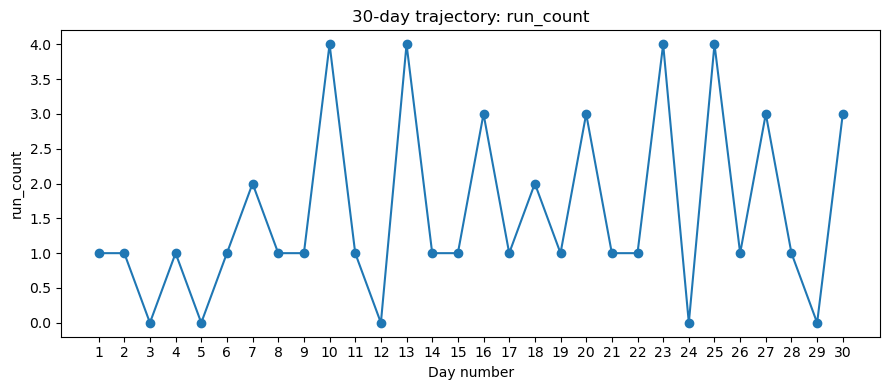

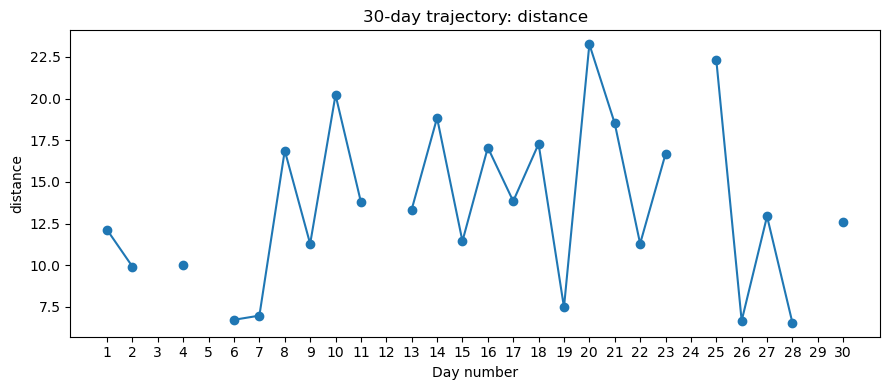

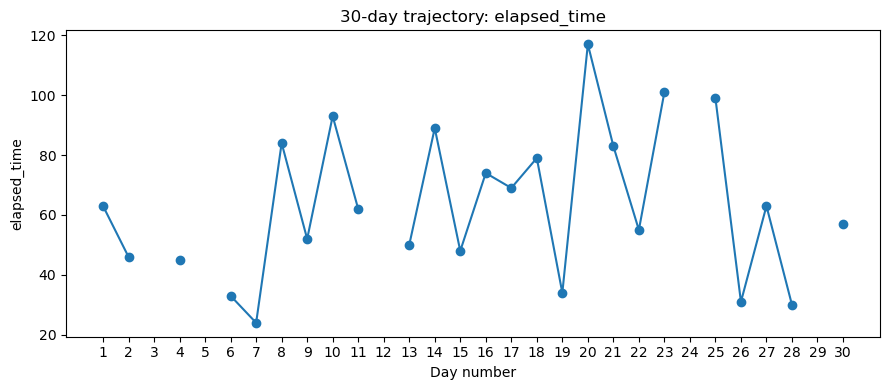

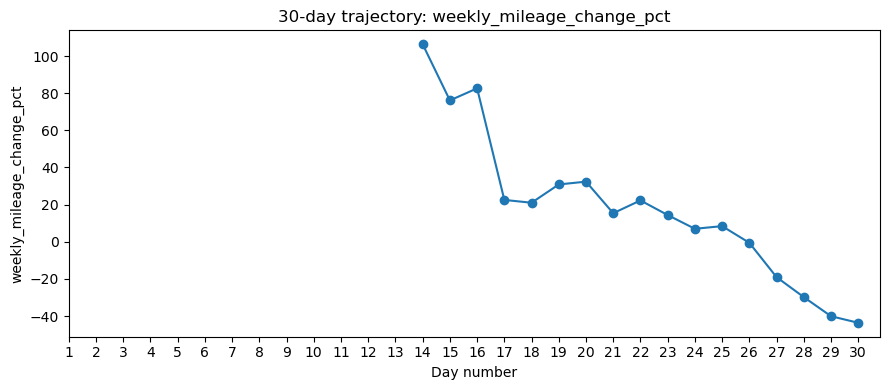

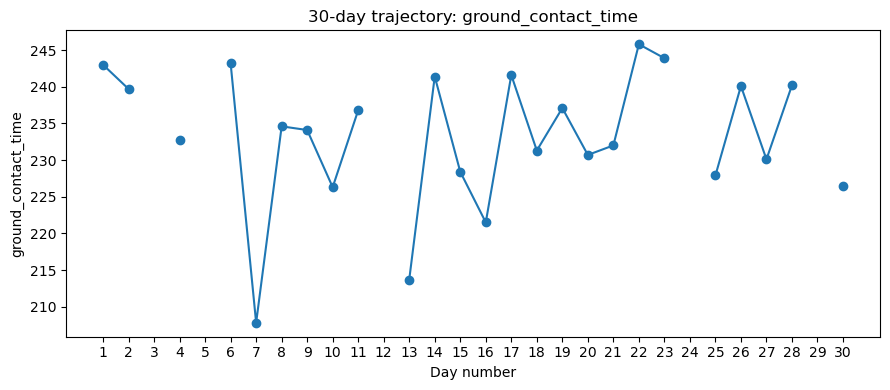

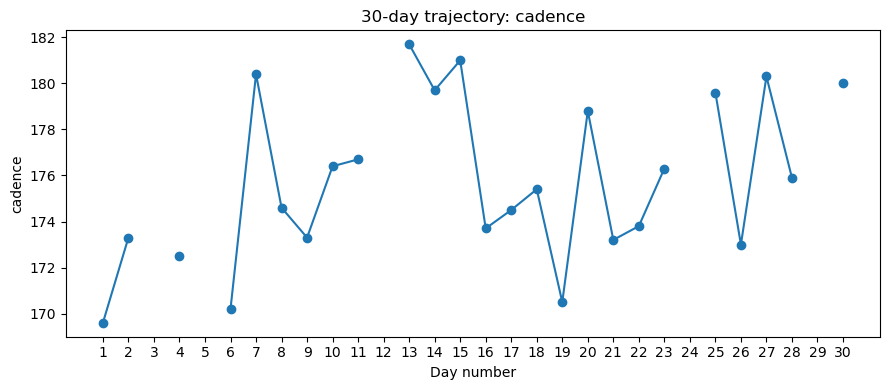

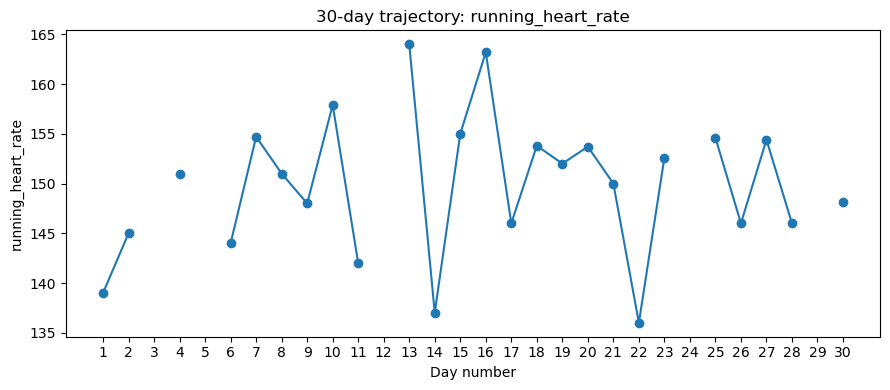

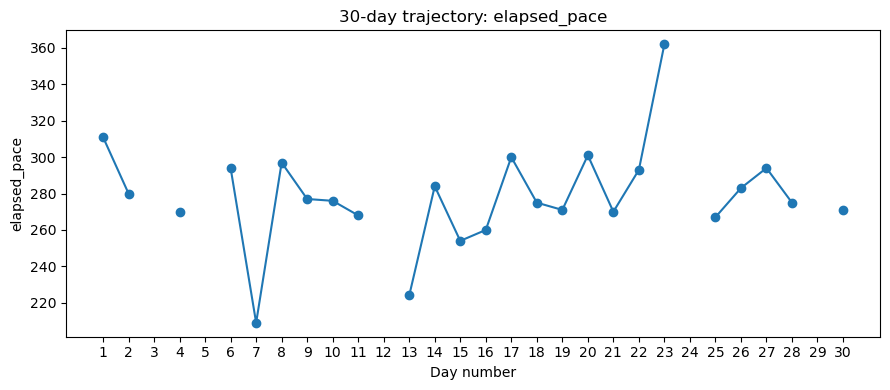

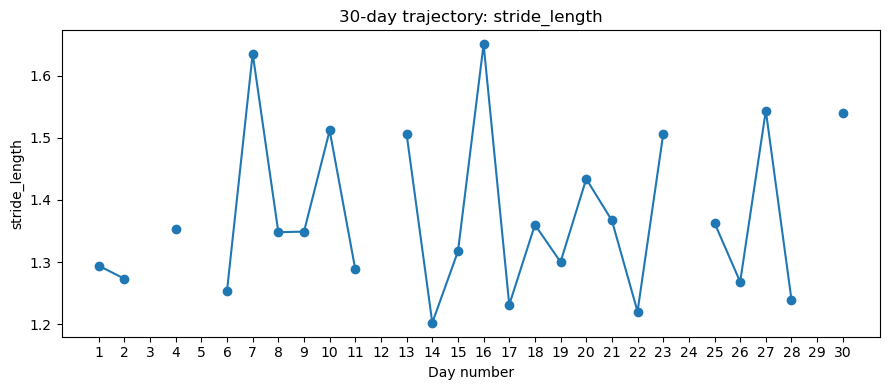

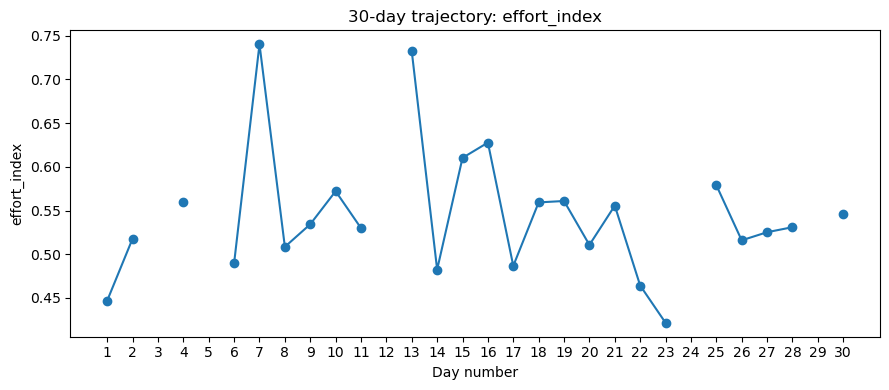

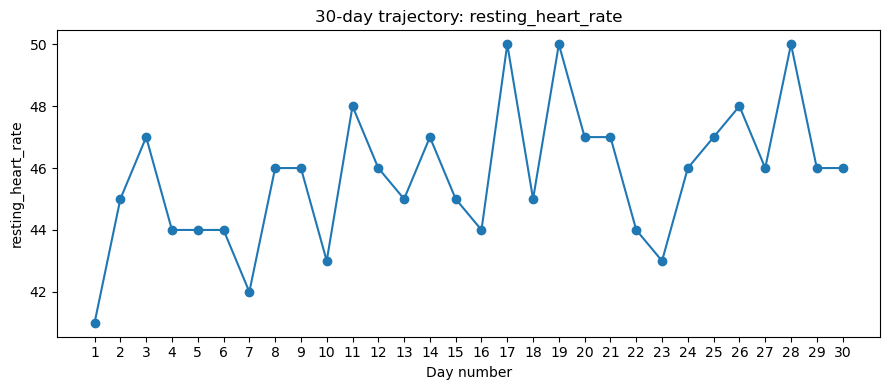

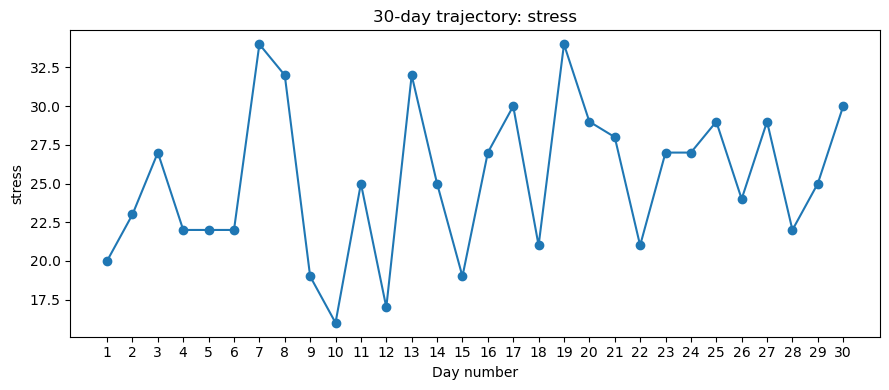

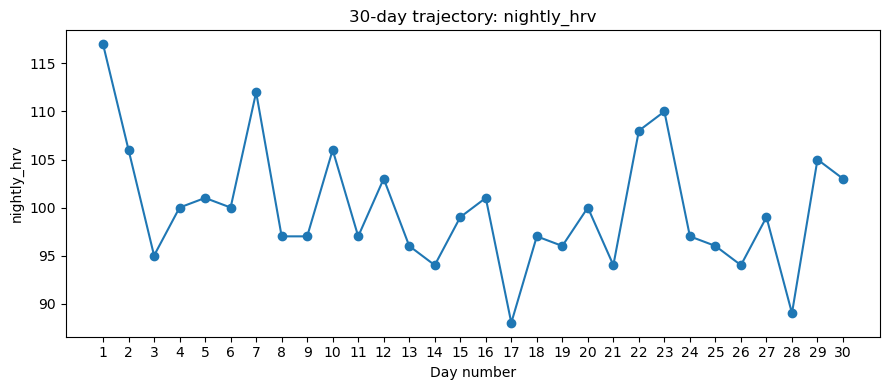

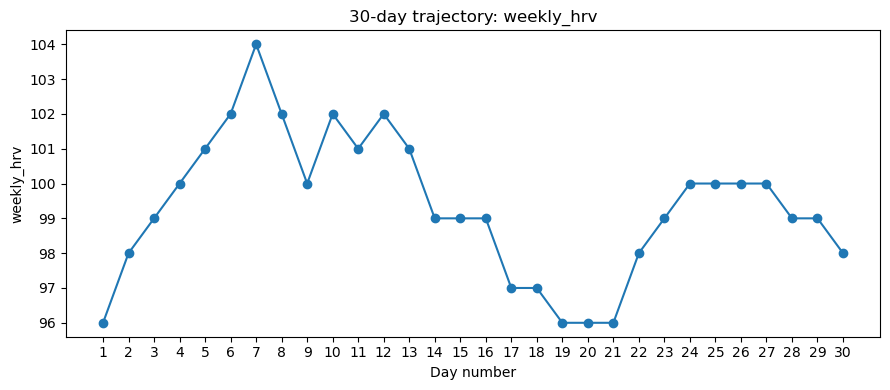

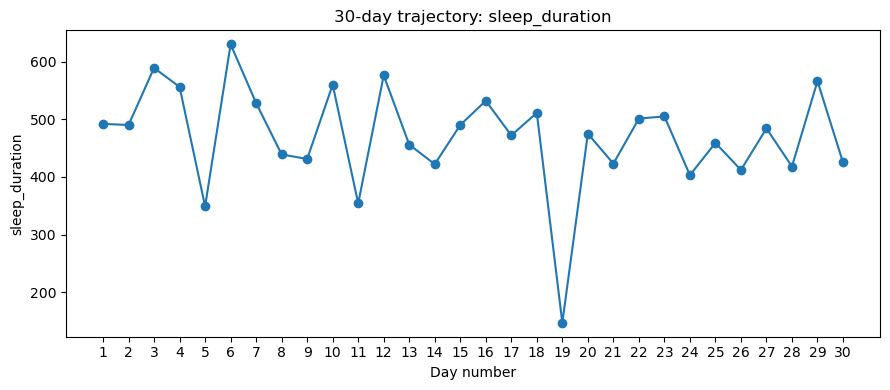

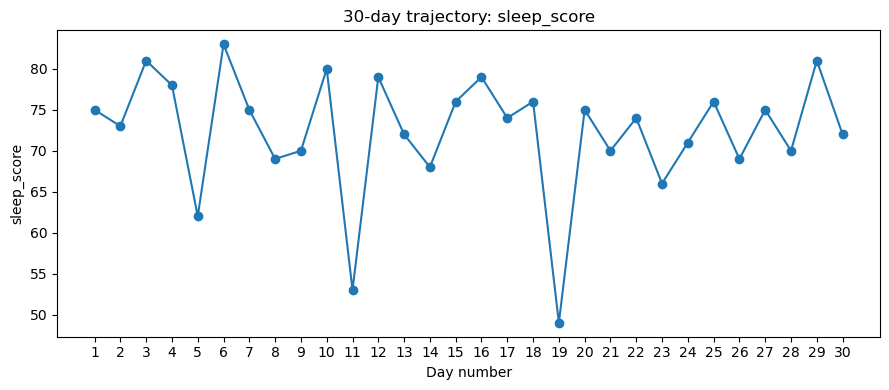

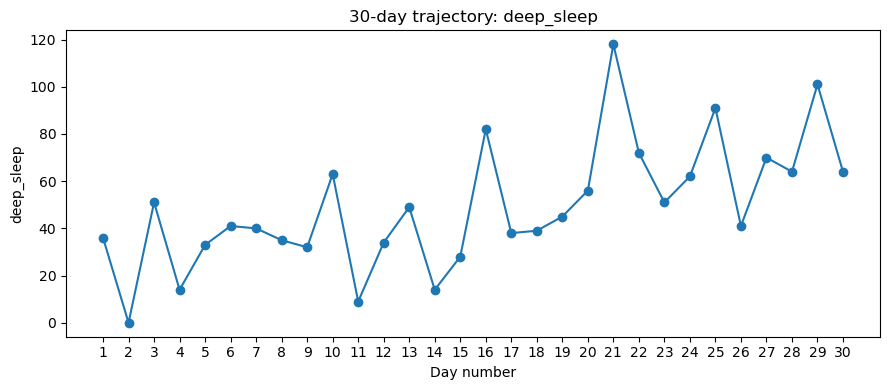

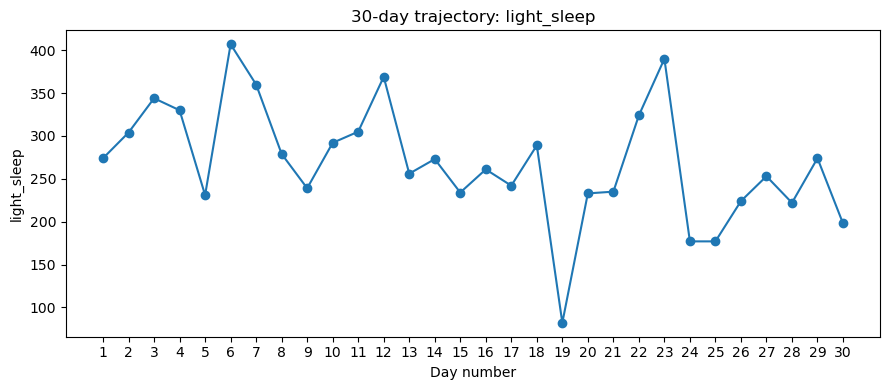

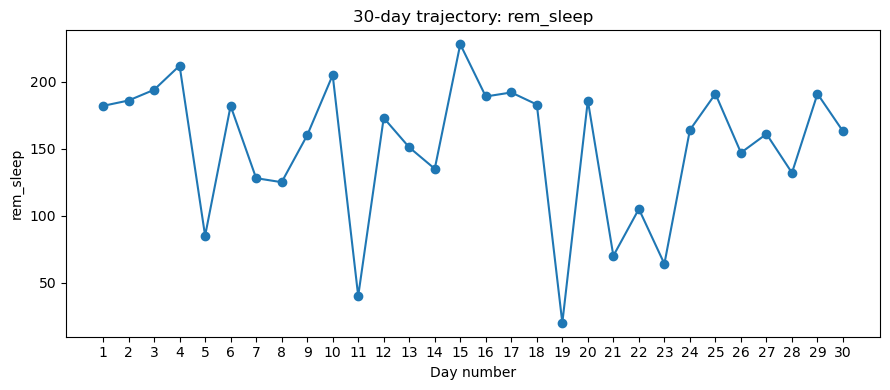

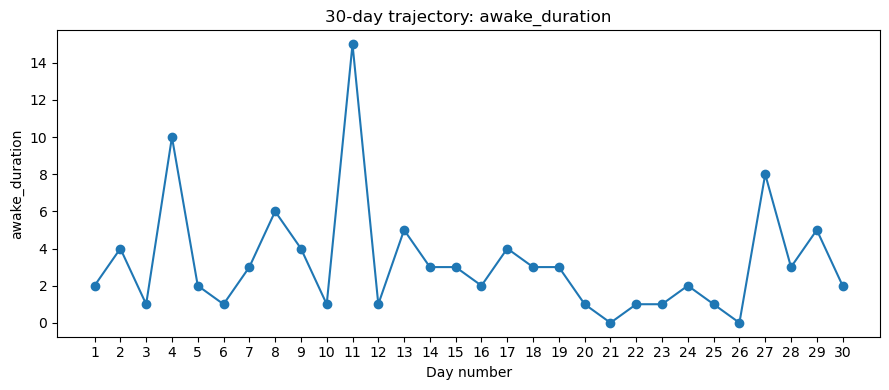

In [90]:
for feature in all_features:
    plt.figure(figsize=(9, 4))

    plt.plot(
        df["day_number"],
        df[feature],
        marker="o"
    )

    plt.title(f"30-day trajectory: {feature}")
    plt.xlabel("Day number")
    plt.ylabel(feature)
    plt.xticks(range(1, 31))
    plt.tight_layout()
    plt.show()


## 16. Seven-day rolling averages

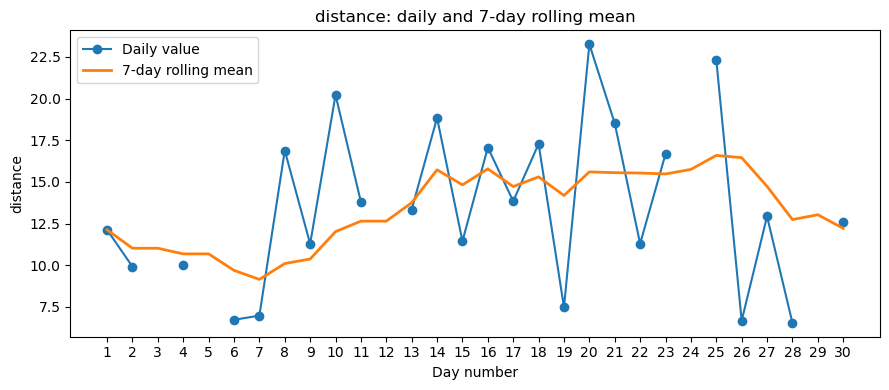

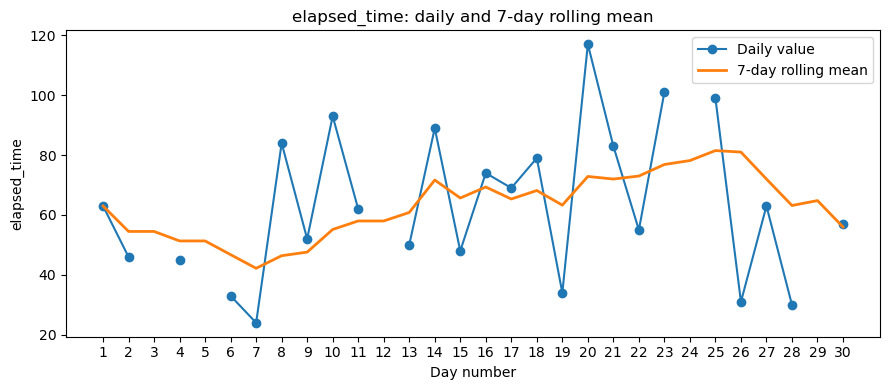

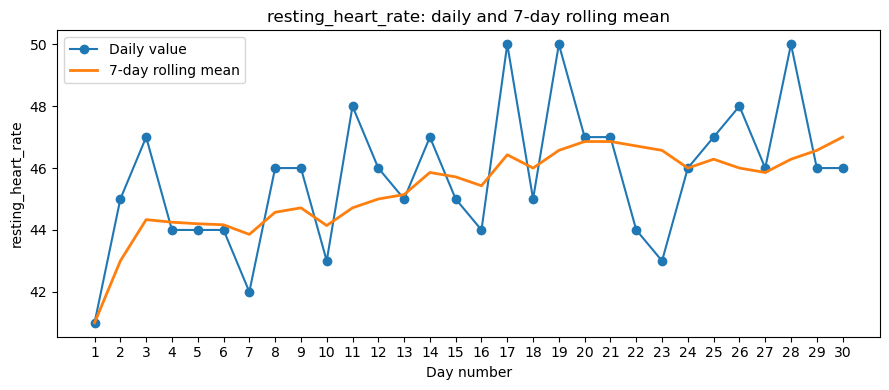

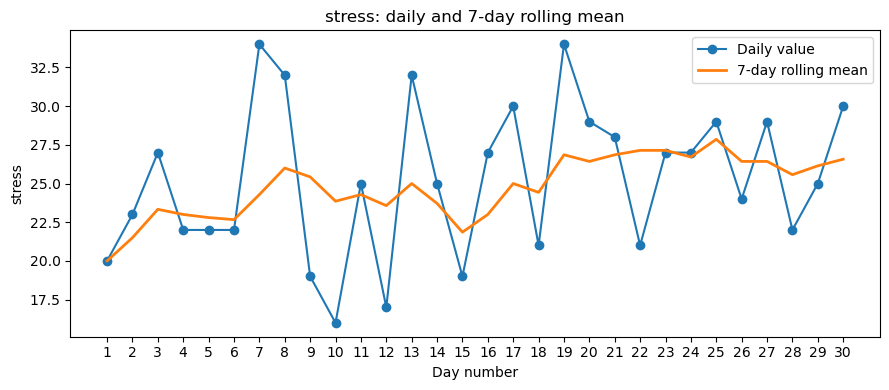

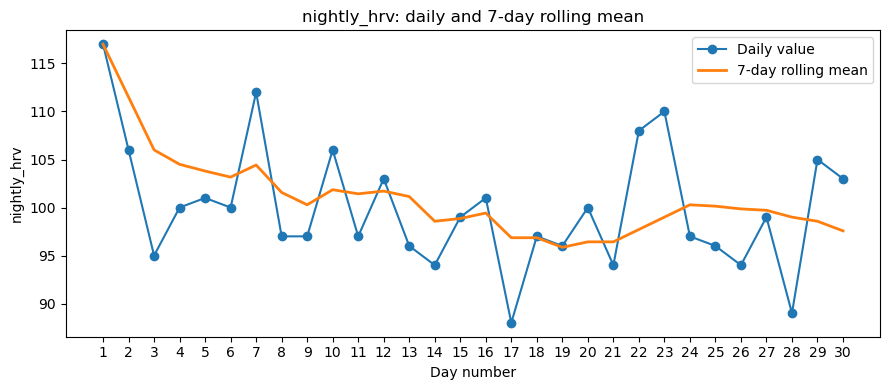

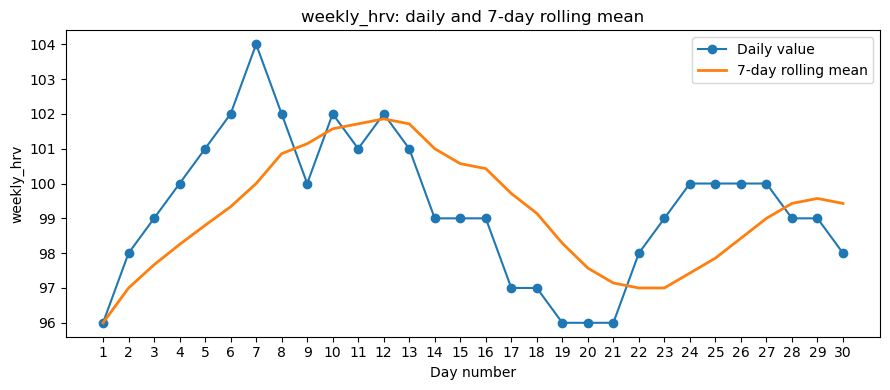

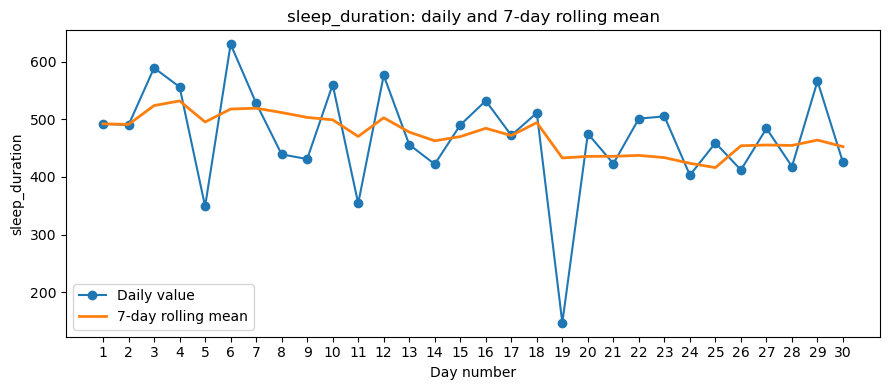

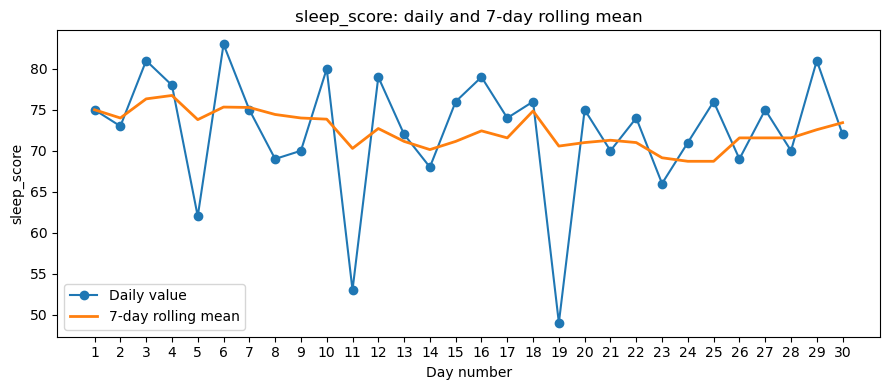

In [91]:
rolling_features = [
    "distance",
    "elapsed_time",
    "resting_heart_rate",
    "stress",
    "nightly_hrv",
    "weekly_hrv",
    "sleep_duration",
    "sleep_score",
]

for feature in rolling_features:
    rolling_mean = (
        df[feature]
        .rolling(
            window=7,
            min_periods=1
        )
        .mean()
    )

    plt.figure(figsize=(9, 4))

    plt.plot(
        df["day_number"],
        df[feature],
        marker="o",
        label="Daily value"
    )

    plt.plot(
        df["day_number"],
        rolling_mean,
        linewidth=2,
        label="7-day rolling mean"
    )

    plt.title(f"{feature}: daily and 7-day rolling mean")
    plt.xlabel("Day number")
    plt.ylabel(feature)
    plt.xticks(range(1, 31))
    plt.legend()
    plt.tight_layout()
    plt.show()


## Percentage Change Plot 

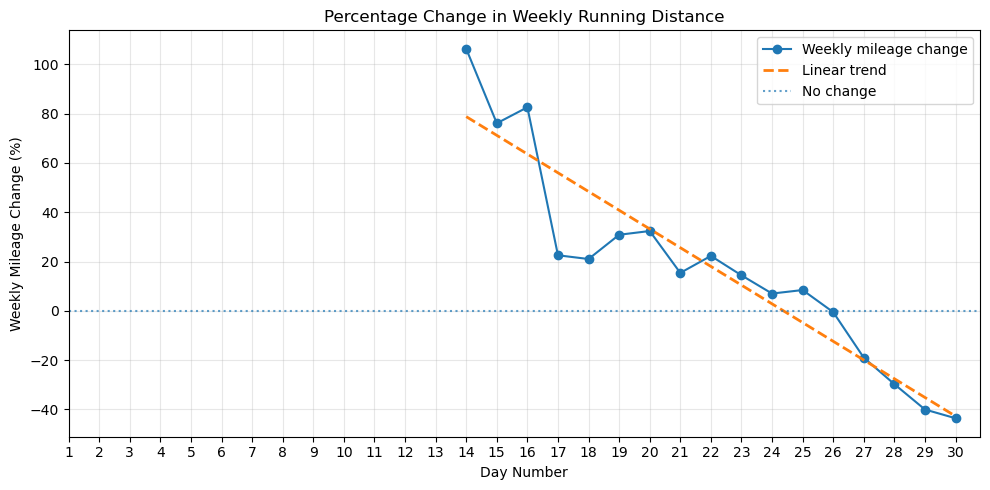

In [92]:

# =====================================================
# Plot Weekly Mileage Percentage Change + Trend Line
# =====================================================

plt.figure(figsize=(10, 5))

# Plot actual weekly mileage percentage change
plt.plot(
    df["day_number"],
    df["weekly_mileage_change_pct"],
    marker="o",
    label="Weekly mileage change"
)

# Only use days where the percentage change can be calculated
trend_data = df[
    ["day_number", "weekly_mileage_change_pct"]
].dropna()

# Calculate linear trend
if len(trend_data) >= 2:

    slope, intercept = np.polyfit(
        trend_data["day_number"],
        trend_data["weekly_mileage_change_pct"],
        1
    )

    trend_line = (
        slope * trend_data["day_number"]
        + intercept
    )

    plt.plot(
        trend_data["day_number"],
        trend_line,
        linestyle="--",
        linewidth=2,
        label="Linear trend"
    )

# Zero line = no change from previous week
plt.axhline(
    y=0,
    linestyle=":",
    alpha=0.7,
    label="No change"
)

plt.xlabel("Day Number")
plt.ylabel("Weekly Mileage Change (%)")

plt.title(
    "Percentage Change in Weekly Running Distance"
)

plt.xticks(range(1, 31))

plt.grid(alpha=0.3)

plt.legend()

plt.tight_layout()

plt.show()

In [93]:
# =====================================================
# Weekly Mileage Increase Summary
# =====================================================

THRESHOLD = 10

# Only use days where weekly change can actually be calculated
valid_weekly_change = df[
    df["weekly_mileage_change_pct"].notna()
].copy()

# Flag increases above 10%
valid_weekly_change["above_10_percent"] = (
    valid_weekly_change["weekly_mileage_change_pct"] > THRESHOLD
)

# Count threshold exceedances
times_above_10 = int(
    valid_weekly_change["above_10_percent"].sum()
)

# Number of valid comparison days
valid_days = len(valid_weekly_change)

# Percentage of valid days exceeding threshold
percentage_above_10 = (
    times_above_10 / valid_days * 100
    if valid_days > 0
    else np.nan
)

# Maximum increase
max_weekly_increase = (
    valid_weekly_change[
        "weekly_mileage_change_pct"
    ].max()
)

# Average weekly change
average_weekly_change = (
    valid_weekly_change[
        "weekly_mileage_change_pct"
    ].mean()
)

# Day of maximum increase
if not valid_weekly_change.empty:
    max_increase_day = valid_weekly_change.loc[
        valid_weekly_change[
            "weekly_mileage_change_pct"
        ].idxmax(),
        "day_number"
    ]
else:
    max_increase_day = np.nan


print("WEEKLY MILEAGE LOAD SUMMARY")
print("-" * 40)

print(
    f"Days with >10% increase: "
    f"{times_above_10}"
)

print(
    f"Percentage of valid comparison days >10%: "
    f"{percentage_above_10:.1f}%"
)

print(
    f"Maximum weekly mileage increase: "
    f"{max_weekly_increase:.1f}%"
)

print(
    f"Day of maximum increase: "
    f"{max_increase_day}"
)

print(
    f"Average weekly mileage change: "
    f"{average_weekly_change:.1f}%"
)

WEEKLY MILEAGE LOAD SUMMARY
----------------------------------------
Days with >10% increase: 10
Percentage of valid comparison days >10%: 58.8%
Maximum weekly mileage increase: 106.4%
Day of maximum increase: 14
Average weekly mileage change: 18.0%


## 17. Within-sample trend slopes

In [94]:
def calculate_slope(dataframe, feature):
    valid = dataframe[
        ["day_number", feature]
    ].dropna()

    if len(valid) < 2:
        return np.nan

    slope, intercept = np.polyfit(
        valid["day_number"],
        valid[feature],
        1
    )

    return slope


trend_table = pd.DataFrame({
    "feature": all_features,
    "daily_slope": [
        calculate_slope(df, feature)
        for feature in all_features
    ],
})

trend_table["30_day_change_estimate"] = (
    trend_table["daily_slope"] * 29
)

display(
    trend_table.sort_values(
        "daily_slope",
        key=abs,
        ascending=False
    )
)


,feature,daily_slope,30_day_change_estimate
3,weekly_mileage_change_pct,-7.601389,-220.440294
17,light_sleep,-3.532369,-102.438710
14,sleep_duration,-2.430923,-70.496774
16,deep_sleep,1.909900,55.387097
18,rem_sleep,-0.808454,-23.445161
2,elapsed_time,0.497199,14.418760
7,elapsed_pace,0.494981,14.354445
12,nightly_hrv,-0.202670,-5.877419
5,cadence,0.150871,4.375252
11,stress,0.142825,4.141935


## 18. Within-sample z-scores

In [95]:
z_score_df = df[
    ["day_number"]
].copy()

for feature in all_features:
    mean_value = df[feature].mean()
    std_value = df[feature].std()

    if pd.isna(std_value) or std_value == 0:
        z_score_df[f"{feature}_z"] = np.nan
    else:
        z_score_df[f"{feature}_z"] = (
            df[feature] - mean_value
        ) / std_value

display(z_score_df.head())


,day_number,run_count_z,distance_z,elapsed_time_z,weekly_mileage_change_pct_z,ground_contact_time_z,cadence_z,running_heart_rate_z,elapsed_pace_z,stride_length_z,effort_index_z,resting_heart_rate_z,stress_z,nightly_hrv_z,weekly_hrv_z,sleep_duration_z,sleep_score_z,deep_sleep_z,light_sleep_z,rem_sleep_z,awake_duration_z
0,1,-0.434320,-0.283541,-0.009572,NaN,1.044561,-1.722476,-1.510600,1.139427,-0.612291,-1.304466,-2.140060,-1.075157,2.650913,-1.620744,0.243355,0.349857,-0.491125,0.069027,0.584896,-0.389098
1,2,-0.434320,-0.731900,-0.687573,NaN,0.692102,-0.690552,-0.671378,0.047887,-0.772617,-0.354273,-0.331559,-0.462726,0.945647,-0.648298,0.221398,0.084143,-1.840782,0.506523,0.661520,0.241872
2,3,-1.200767,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.572692,0.353849,-0.759618,-0.162074,1.308263,1.146999,0.071232,1.089850,0.814768,-0.704584
3,4,-0.434320,-0.713641,-0.727456,NaN,-0.044858,-0.913671,0.167844,-0.304223,-0.161852,0.200500,-0.783684,-0.666869,0.015502,0.324149,0.945975,0.748428,-1.315916,0.885686,1.159576,2.134784
4,5,-1.200767,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.783684,-0.666869,0.170527,0.810372,-1.326560,-1.377285,-0.603597,-0.558050,-1.273234,-0.389098


## 19. Extreme within-sample observations

In [96]:
z_columns = [
    column for column in z_score_df.columns
    if column.endswith("_z")
]

extreme_counts = (
    z_score_df[z_columns]
    .abs()
    .gt(2.5)
    .sum()
    .sort_values(ascending=False)
)

display(
    extreme_counts
    .rename("observations_with_abs_z_above_2_5")
    .to_frame()
)


,observations_with_abs_z_above_2_5
sleep_score_z,2
effort_index_z,2
ground_contact_time_z,1
elapsed_pace_z,1
awake_duration_z,1
light_sleep_z,1
nightly_hrv_z,1
rem_sleep_z,1
deep_sleep_z,1
sleep_duration_z,1


## 20. IQR outlier summary

In [97]:
outlier_records = []

for feature in all_features:
    values = df[feature].dropna()

    if values.empty:
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (values < lower_bound)
        | (values > upper_bound)
    ).sum()

    outlier_records.append({
        "feature": feature,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": int(outlier_count),
    })

outlier_summary = pd.DataFrame(
    outlier_records
).set_index("feature")

display(
    outlier_summary.sort_values(
        "outlier_count",
        ascending=False
    )
)


,lower_bound,upper_bound,outlier_count
feature,,,
effort_index,0.429715,0.639588,3
elapsed_pace,234.000000,330.000000,3
weekly_mileage_change_pct,-47.674328,77.979762,2
awake_duration,-3.500000,8.500000,2
rem_sleep,40.125000,277.125000,2
sleep_score,61.000000,85.000000,2
ground_contact_time,210.700000,257.900000,1
sleep_duration,273.125000,674.125000,1
deep_sleep,-10.000000,108.000000,1


## 21. Correlation matrix

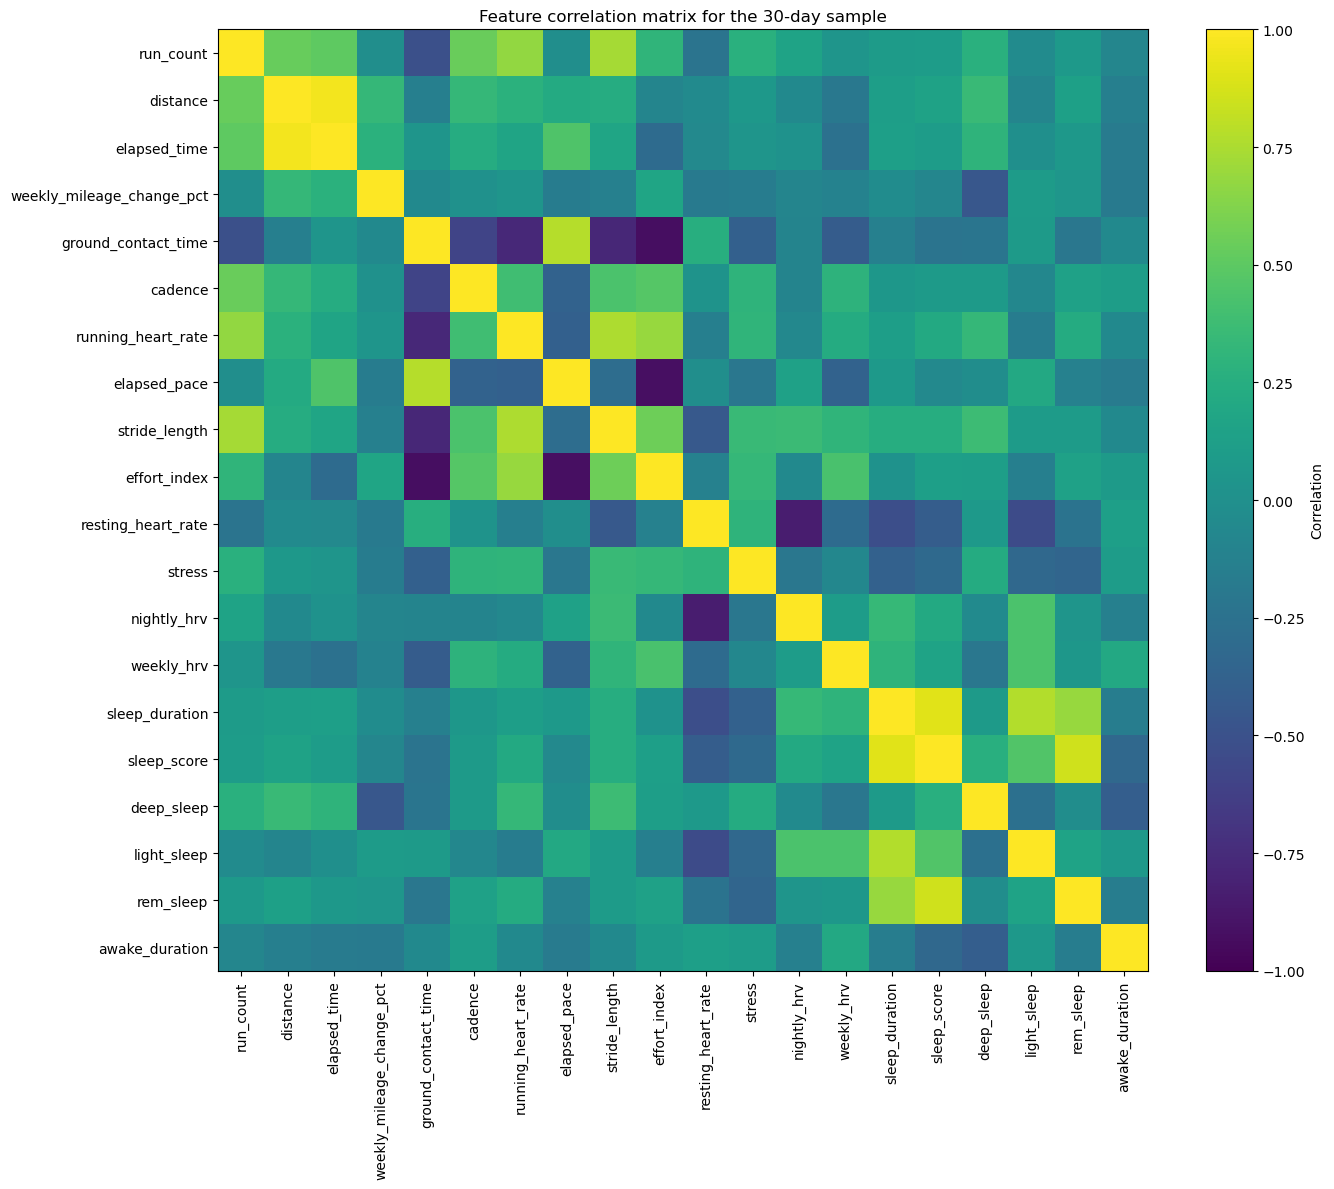

,run_count,distance,elapsed_time,weekly_mileage_change_pct,ground_contact_time,cadence,running_heart_rate,elapsed_pace,stride_length,effort_index,resting_heart_rate,stress,nightly_hrv,weekly_hrv,sleep_duration,sleep_score,deep_sleep,light_sleep,rem_sleep,awake_duration
run_count,1.00,0.54,0.50,-0.01,-0.51,0.54,0.67,-0.01,0.73,0.31,-0.23,0.27,0.16,0.04,0.10,0.11,0.27,-0.03,0.08,-0.08
distance,0.54,1.00,0.97,0.33,-0.14,0.34,0.28,0.22,0.24,-0.09,-0.04,0.06,-0.05,-0.20,0.12,0.15,0.35,-0.09,0.13,-0.14
elapsed_time,0.50,0.97,1.00,0.28,0.05,0.24,0.17,0.45,0.18,-0.30,-0.06,0.04,0.02,-0.26,0.13,0.11,0.30,-0.01,0.07,-0.16
weekly_mileage_change_pct,-0.01,0.33,0.28,1.00,-0.05,0.01,0.04,-0.16,-0.13,0.18,-0.19,-0.16,-0.09,-0.11,-0.03,-0.08,-0.46,0.10,0.05,-0.18
ground_contact_time,-0.51,-0.14,0.05,-0.05,1.00,-0.59,-0.77,0.78,-0.78,-0.93,0.26,-0.39,-0.09,-0.42,-0.13,-0.23,-0.22,0.09,-0.21,-0.05
cadence,0.54,0.34,0.24,0.01,-0.59,1.00,0.39,-0.37,0.43,0.47,0.03,0.30,-0.10,0.30,0.06,0.09,0.09,-0.08,0.15,0.11
running_heart_rate,0.67,0.28,0.17,0.04,-0.77,0.39,1.00,-0.39,0.76,0.69,-0.14,0.31,-0.06,0.23,0.12,0.22,0.33,-0.16,0.23,-0.05
elapsed_pace,-0.01,0.22,0.45,-0.16,0.78,-0.37,-0.39,1.00,-0.28,-0.92,-0.01,-0.21,0.15,-0.37,0.08,-0.06,-0.02,0.20,-0.12,-0.16
stride_length,0.73,0.24,0.18,-0.13,-0.78,0.43,0.76,-0.28,1.00,0.56,-0.44,0.36,0.37,0.31,0.25,0.25,0.37,0.10,0.10,-0.05
effort_index,0.31,-0.09,-0.30,0.18,-0.93,0.47,0.69,-0.92,0.56,1.00,-0.12,0.33,-0.05,0.42,0.02,0.13,0.12,-0.14,0.14,0.09


In [98]:
correlation_matrix = df[all_features].corr()

plt.figure(figsize=(14, 12))

image = plt.imshow(
    correlation_matrix,
    aspect="auto",
    vmin=-1,
    vmax=1
)

plt.colorbar(image, label="Correlation")

plt.xticks(
    range(len(all_features)),
    all_features,
    rotation=90
)

plt.yticks(
    range(len(all_features)),
    all_features
)

plt.title("Feature correlation matrix for the 30-day sample")
plt.tight_layout()
plt.show()

display(correlation_matrix.round(2))


## 22. Prepare an imputed modelling copy

In [99]:
df_model = df.copy()

non_running_mask = df_model["run_count"].eq(0)

# On non-running days, running load is zero.
for feature in ["distance", "elapsed_time"]:
    df_model.loc[
        non_running_mask & df_model[feature].isna(),
        feature
    ] = 0

# Running mechanics do not exist on non-running days.
# Fill with the sample median while retaining is_running_day.
for feature in [
    "ground_contact_time",
    "cadence",
    "running_heart_rate",
    "elapsed_pace",
    "stride_length",
]:
    df_model.loc[
        non_running_mask & df_model[feature].isna(),
        feature
    ] = df_model[feature].median()

# Interpolate remaining missing values through time.
for feature in all_features:
    df_model[feature] = (
        df_model[feature]
        .interpolate(limit_direction="both")
        .fillna(df_model[feature].median())
    )

df_model["is_running_day"] = (
    df_model["run_count"] > 0
).astype(int)

print(
    "Remaining missing values:",
    int(
        df_model[
            all_features + ["is_running_day"]
        ]
        .isna()
        .sum()
        .sum()
    )
)


Remaining missing values: 0


## 23. Create aeon-ready array

In [100]:
aeon_features = all_features + ["is_running_day"]

X_single = (
    df_model[aeon_features]
    .to_numpy(dtype=float)
    .T
    [np.newaxis, :, :]
)

print("aeon-ready shape:", X_single.shape)
print("Cases:", X_single.shape[0])
print("Channels:", X_single.shape[1])
print("Time points:", X_single.shape[2])
print("Missing values:", np.isnan(X_single).sum())


aeon-ready shape: (1, 21, 30)
Cases: 1
Channels: 21
Time points: 30
Missing values: 0


The expected shape is:

```text
(1, 19, 30)
```

This means:

- 1 sample
- 19 channels, including `is_running_day`
- 30 time points


## 24. Optional within-sample standardisation

In [101]:
X_single_standardised = X_single.copy()

for channel_index in range(
    X_single_standardised.shape[1]
):
    values = X_single_standardised[
        0,
        channel_index,
        :
    ]

    mean_value = values.mean()
    std_value = values.std()

    if std_value == 0:
        X_single_standardised[
            0,
            channel_index,
            :
        ] = 0
    else:
        X_single_standardised[
            0,
            channel_index,
            :
        ] = (
            values - mean_value
        ) / std_value

print(
    "Standardised shape:",
    X_single_standardised.shape
)


Standardised shape: (1, 21, 30)


### Standardisation warning

For a trained injury-prediction model, do **not** normally standardise a new sample using its own mean and standard deviation.

Instead, apply the means and standard deviations learned from the original model's training data.

The standardised array above is useful for exploratory analysis only unless it matches the preprocessing used during training.


## 25. Save processed outputs

In [102]:
df.to_csv(
    "single_sample_cleaned.csv",
    index=False
)

df_model.to_csv(
    "single_sample_imputed.csv",
    index=False
)

np.save(
    "X_single.npy",
    X_single
)

np.save(
    "X_single_standardised.npy",
    X_single_standardised
)

pd.Series(
    aeon_features,
    name="feature"
).to_csv(
    "single_sample_feature_order.csv",
    index=False
)

trend_table.to_csv(
    "single_sample_trends.csv",
    index=False
)

print("Saved:")
print("- single_sample_cleaned.csv")
print("- single_sample_imputed.csv")
print("- X_single.npy")
print("- X_single_standardised.npy")
print("- single_sample_feature_order.csv")
print("- single_sample_trends.csv")


Saved:
- single_sample_cleaned.csv
- single_sample_imputed.csv
- X_single.npy
- X_single_standardised.npy
- single_sample_feature_order.csv
- single_sample_trends.csv


## 26. Final validation

In [103]:
assert len(df) == 30, (
    "The sample does not contain exactly 30 rows."
)

assert df["day_number"].nunique() == 30, (
    "The sample does not contain 30 unique day numbers."
)

assert X_single.shape == (
    1,
    len(aeon_features),
    30
)

assert not np.isnan(X_single).any()

print("Final validation passed.")
print("The sample is ready for aeon processing.")


Final validation passed.
The sample is ready for aeon processing.


# Important limitation

A single 30-day sample cannot be used to train or evaluate a reliable injury-classification model by itself.

It can be used to:

- inspect one athlete's trajectory
- identify unusual days
- calculate trends
- prepare the sample for input into an already trained model
- compare predicted risk from an existing classifier

The model used for prediction must have been trained previously on multiple labelled samples.
